In [ ]:
#Cell 1: imports and devices

In [6]:

import os, sys, math, glob, json, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
from scipy.signal import welch, butter, filtfilt
from scipy.stats import kurtosis
import mne

# GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    try:
        print("GPU:", torch.cuda.get_device_name(0))
    except:
        pass


Device: cuda
GPU: NVIDIA GeForce GTX 1650 Ti


In [2]:
##Cell 2: Checking GPU Availability and Importing the dataset
1) Creates a Subjects Range from 1 to 66 patients  
2) sampling rate in dataset = 500 readings every second
3) 5-second windows --> cuts EEG data into 5-second pieces
4) 50% overlap --> 50% overlap between EEG segments
5) number of Channels = 19

In [7]:
##Cell 2
datasetPath = r"C:\Users\sanja\Desktop\EEG_Project\EEG\eeg"  
subjects = [f"sub-{i:03d}" for i in range(1,66)]  
fs_target = 500  # sampling rate in dataset (already 500)
seg_sec = 5      # 5-second windows
overlap = 0.5    # 50% overlap
window_samples = int(seg_sec * fs_target)
step_samples = int(window_samples * (1 - overlap))
n_channels_expected = 19
save_dir = Path("results_bilstm")
save_dir.mkdir(exist_ok=True)


In [ ]:
# Cell 3: ueses wavelet-packet proxy

In [8]:
# Cell 3
use_tqwt = False
try:
    import tqwt  # preferred package if available
    use_tqwt = True
    print("tqwt package available.")
except Exception as e:
    print("tqwt not found. Will use fallback (wavelet-packet approx) if necessary.")
    use_tqwt = False

# Fallback: we'll use pywt WaveletPacket as approximate multi-band split when tqwt unavailable
try:
    import pywt
    has_pywt = True
except:
    has_pywt = False
    raise ImportError("pywt not installed. Please install pywt (pip install PyWavelets).")


tqwt not found. Will use fallback (wavelet-packet approx) if necessary.


In [ ]:
Cell 4: 
This cell extracts useful information (features) from raw 
EEG signals so that the Bi-LSTM model can understand them better.
Entropy --> quantify the impurity, disorder, or uncertainty within a dataset.
1) shannon_entropy --> How random or unpredictable the EEG signal is
2) tsallis_entropy --> Finding rare spikes in EEG that normal measures might miss
3) renyi_entropy --> Measures how concentrated the EEG signal is
4) katz_fd --> Signal complexity,How rough or jagged the EEG signal is
5) kurtosis_feature --> Peakedness of the EEG signal

In [9]:
# Cell 4: feature functions
def shannon_entropy(x, bins=100):
    p, _ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    return -np.sum(p * np.log2(p))

def tsallis_entropy(x, q=2.0, bins=100):
    p,_ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    if q == 1.0:
        return -np.sum(p * np.log(p))
    return (1.0 - np.sum(p**q)) / (q - 1.0)

def renyi_entropy(x, q=0.5, bins=100):
    p,_ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    return (1.0/(1.0 - q)) * np.log(np.sum(p**q))

def katz_fd(x):
    x = np.asarray(x)
    n = len(x)
    if n < 2:
        return 0.0
    L = np.sum(np.sqrt(1 + np.diff(x)**2))
    d = np.max(np.sqrt((np.arange(n) - 0)**2 + (x - x[0])**2))
    if L == 0 or d == 0:
        return 0.0
    return np.log10(n) / (np.log10(n) + np.log10(d / L))

def kurtosis_feature(x):
    return float(kurtosis(x, fisher=False, nan_policy='omit'))

# wrapper to compute 4 features from a 1D subband
def features_from_subband(x):
    x = np.asarray(x)
    if x.std() == 0:
        x = x - x.mean()
    return [katz_fd(x), tsallis_entropy(x, q=2.0), renyi_entropy(x, q=0.5), kurtosis_feature(x)]


In [10]:
# Cell 5: estimate Q,R,J from signal power (simple heuristic)
def estimate_tqwt_params(signal, fs):
    # PSD to find dominant freq f0 and approximate bandwidth
    f, Pxx = welch(signal, fs=fs, nperseg=min(len(signal), 2048))## Welches Methods 
    f0 = f[np.argmax(Pxx)]                                       ##Finds frequency with maximum power(This is the strongest brain rhythm)
    # half-power bandwidth approx
    peak = np.max(Pxx)
    inds = np.where(Pxx >= peak/2)[0]
    if len(inds) > 1:
        bw = f[inds[-1]] - f[inds[0]]
    else:
        bw = max(1.0, f0*0.5)
    Q = max(0.5, float(f0) / max(bw, 1e-6))
    # redundancy heuristic: bound between 2 and 12
    R = int(np.clip(fs / (2 * max(f0,1.0)), 2, 12))
    # J selection: want ~2 Hz subband width: J ~ log2((fs/2)/target_bw)
    target_bw = 2.0
    J = int(np.clip(np.floor(np.log2((fs/2)/target_bw)), 3, 8))
    return float(Q), int(R), int(J)

# quick test (won't run until dataset provided)
# print(estimate_tqwt_params(np.random.randn(1000), fs_target))


In [11]:
# Cell 6: decomposition function returning list of subband time-series (length J+1)
def decompose_tqwt(signal, Q, R, J, fs):
    # Try tqwt library if available
    if use_tqwt:
        try:
            # tqwt API vary. Example: tqwt.tqwt(signal, Q, r, J) -> coeffs or subbands
            coeffs = tqwt.tqwt(signal, Q, R, J)  # may require adaptation
            # user must adapt if API differs. We'll expect reconstructed subbands returned.
            return coeffs
        except Exception as e:
            pass
    # Fallback: use wavelet packet decomposition to produce J+1 components
    wp = pywt.WaveletPacket(data=signal, wavelet='db4', mode='symmetric', maxlevel=J)
    # Collect nodes at level J (details approximating bands)
    nodes = [node.path for node in wp.get_level(J, order='freq')]
    subbands = []
    for path in nodes:
        node_data = wp[path].data
        # Reconstruct node to full length via inverse transform on that node only
        # Simpler: upsample node_data to original length by interpolation
        up = np.interp(np.linspace(0, len(node_data)-1, len(signal)), np.arange(len(node_data)), node_data)
        subbands.append(up)
    # ensure we return exactly J+1 bands; if fewer, pad with zeros
    if len(subbands) < J+1:
        for _ in range(J+1 - len(subbands)):
            subbands.append(np.zeros_like(signal))
    return subbands[:J+1]


In [16]:
# Cell 7 (updated): load subject file list and labels from labels.csv

import pandas as pd
from pathlib import Path

data_root = Path(datasetPath)
label_file = Path(r"C:\Users\sanja\Desktop\EEG_Project\EEG\eeg\derivatives\labels.csv")  # path to your labels.csv
labels_df = pd.read_csv(label_file)

# Normalize label text and build dictionary
labels = {}
for _, row in labels_df.iterrows():
    sid = str(row['subject']).strip()
    lab = str(row['label']).lower()
    if 'ad' in lab or 'alzheimer' in lab:
        labels[sid] = 1
    elif 'control' in lab or 'cn' in lab or 'healthy' in lab:
        labels[sid] = 0
    elif lab in ['1','0']:
        labels[sid] = int(lab)
    else:
        labels[sid] = None

# Build manifest: subject, EEG file path, label
manif = []
for sub in subjects:
    subdir = data_root / sub
    if not subdir.exists():
        subdir = next(data_root.glob(f"**/{sub}"), None)
        if subdir is None:
            print("Missing:", sub)
            continue
    eeg_files = list(subdir.glob("**/*.set")) + list(subdir.glob("**/*.edf")) + list(subdir.glob("**/*.bdf"))
    if not eeg_files:
        print("No EEG file for", sub)
        continue
    filepath = eeg_files[0]
    label = labels.get(sub, None)
    if label is None:
        print("Label missing for", sub, "- skipping.")
        continue
    manif.append((sub, str(filepath), int(label)))

print("Subjects collected:", len(manif))
print("Example:", manif[:3])


Subjects collected: 65
Example: [('sub-001', 'C:\\Users\\sanja\\Desktop\\EEG_Project\\EEG\\eeg\\sub-001\\eeg\\sub-001_task-eyesclosed_eeg.set', 1), ('sub-002', 'C:\\Users\\sanja\\Desktop\\EEG_Project\\EEG\\eeg\\sub-002\\eeg\\sub-002_task-eyesclosed_eeg.set', 1), ('sub-003', 'C:\\Users\\sanja\\Desktop\\EEG_Project\\EEG\\eeg\\sub-003\\eeg\\sub-003_task-eyesclosed_eeg.set', 1)]


In [19]:
# Cell 8: segmentation and live TQWT feature extraction (fixed)

def bandpass(x, lo=0.5, hi=45, fs=fs_target, order=4):
    b, a = butter(order, [lo/(fs/2), hi/(fs/2)], btype='band')
    return filtfilt(b, a, x)

all_features = []
all_labels = []
all_subject_idx = []

for subj_idx, (sub, filepath, label) in enumerate(manif):
    print(f"\nProcessing {sub} ({subj_idx+1}/{len(manif)}) label={label}")

    # --- Load EEG (.set) safely ---
    try:
        raw = mne.io.read_raw_eeglab(filepath, preload=True, verbose='ERROR')
    except Exception:
        raw = mne.io.read_raw_eeglab(filepath, preload=False, verbose='ERROR')
        raw.load_data()

    raw.pick_types(eeg=True)
    data = raw.get_data()
    n_ch, n_samps = data.shape
    fs = raw.info['sfreq']

    # --- Bandpass filter (0.5–45 Hz) ---
    for ci in range(n_ch):
        data[ci] = bandpass(data[ci], 0.5, 45, fs)

    # --- Segment into 5s windows (50% overlap) ---
    total_segments = 0
    for start in range(0, int(n_samps - window_samples), step_samples):
        end = start + window_samples
        if end > n_samps:
            break
        seg = data[:, start:end]
        if seg.shape[1] < window_samples:
            continue

        total_segments += 1
        # Estimate data-driven TQWT parameters (Q, R, J)
        Q, R, J = estimate_tqwt_params(seg[0], fs)
        seg_feats = []

        # --- TQWT decomposition and feature extraction ---
        for ch in range(n_ch):
            subbands = decompose_tqwt(seg[ch], Q, R, J, fs)
            for sb in subbands:
                seg_feats.extend(features_from_subband(sb))

        expected_len = (J + 1) * 4 * n_channels_expected
        if len(seg_feats) < expected_len:
            seg_feats += [0.0] * (expected_len - len(seg_feats))

        all_features.append(seg_feats)
        all_labels.append(label)
        all_subject_idx.append(sub)

    print(f"{sub}: {total_segments} segments extracted.")

    # --- Save checkpoint every 5 subjects ---
    if (subj_idx + 1) % 5 == 0:
        np.save(save_dir / "features_checkpoint.npy", np.array(all_features, dtype=object))
        pd.DataFrame({"label": all_labels, "sub": all_subject_idx}).to_csv(
            save_dir / "labels_checkpoint.csv", index=False
        )

print("\nFeature extraction done. Total segments:", len(all_features))
X = np.array(all_features, dtype=np.float32)
y = np.array(all_labels, dtype=np.int64)
print("X shape:", X.shape, "y shape:", y.shape)



Processing sub-001 (1/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-001: 238 segments extracted.

Processing sub-002 (2/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-002: 316 segments extracted.

Processing sub-003 (3/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-003: 121 segments extracted.

Processing sub-004 (4/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-004: 281 segments extracted.

Processing sub-005 (5/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-005: 320 segments extracted.

Processing sub-006 (6/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-006: 253 segments extracted.

Processing sub-007 (7/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-007: 306 segme

In [20]:
# Cell 9: PyTorch Dataset
class EEGFeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# standardize features (fit on all for now; better: fit on train in CV loop)
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_scaled = sc.fit_transform(X)
np.save(save_dir/"scaler_mean.npy", sc.mean_)
np.save(save_dir/"scaler_scale.npy", sc.scale_)

dataset = EEGFeatureDataset(X_scaled, y)


In [21]:
# Cell 10: mixup augmentation
def mixup_data(x, y, alpha=0.4):
    '''Returns mixed inputs, pairs of targets, and lambda'''
    if alpha <= 0:
        return x, y, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


In [22]:
# Cell 11: BiLSTM classifier
class BiLSTMClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, n_layers=2, dropout=0.4):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        # treat features as a sequence by splitting into "timesteps"
        # choose a timestep length: we can partition features into channels*subbands steps
        # We'll set timesteps = n_channels_expected and features_per_step = input_dim / timesteps
        self.timesteps = n_channels_expected
        assert input_dim % self.timesteps == 0, "input_dim must be divisible by timesteps"
        self.feat_per_step = input_dim // self.timesteps
        self.lstm = nn.LSTM(self.feat_per_step, hidden_dim, num_layers=n_layers,
                            batch_first=True, bidirectional=True, dropout=dropout)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim*2, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1)
        )
    def forward(self, x):
        # x: batch x input_dim
        b = x.size(0)
        x = x.view(b, self.timesteps, self.feat_per_step)  # batch x timesteps x feat_per_step
        out, _ = self.lstm(x)  # batch x timesteps x (2*hidden_dim)
        # use last timestep
        out = out[:, -1, :]
        out = self.fc(out).squeeze(1)
        return out  # logits


In [23]:
# Cell 12: training + 10-fold CV
from sklearn.utils.class_weight import compute_class_weight
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

INPUT_DIM = X_scaled.shape[1]
EPOCHS = 80
BATCH = 64
best_overall = {"auc":0.0, "model_path": None}

fold = 0
results = []

for train_idx, test_idx in skf.split(X_scaled, y):
    fold += 1
    print(f"\n===== Fold {fold} =====")
    X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # compute class weights for criterion
    cw = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
    weight_tensor = torch.tensor([cw[0], cw[1]]).float().to(device)  # not directly used in BCEWithLogits
    # use pos_weight in BCEWithLogits for binary imbalance: pos_weight = weight of positive class
    # derive pos_weight = cw[1] / cw[0]
    pos_weight = torch.tensor([cw[1]/cw[0]]).float().to(device)

    train_ds = EEGFeatureDataset(X_train, y_train)
    test_ds = EEGFeatureDataset(X_test, y_test)
    train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, drop_last=True)
    test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False)

    model = BiLSTMClassifier(INPUT_DIM, hidden_dim=256, n_layers=2, dropout=0.4).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'max', patience=5, factor=0.5)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)  # handles imbalance

    best_auc = 0.0
    best_model_path = save_dir / f"best_fold{fold}.pt"
    early_stop_count = 0

    for epoch in range(1, EPOCHS+1):
        model.train()
        epoch_loss = 0.0
        all_preds = []
        all_targets = []
        for xb, yb in train_loader:
            xb = xb.to(device).float()
            yb = yb.to(device).float()
            # mixup
            xb, ya, yb2, lam = mixup_data(xb, yb.long(), alpha=0.4)
            xb, ya, yb2 = xb.to(device).float(), ya.to(device).float(), yb2.to(device).float()
            optimizer.zero_grad()
            logits = model(xb)
            loss = mixup_criterion(criterion, logits, ya, yb2, lam)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()*xb.size(0)
            preds = torch.sigmoid(logits).detach().cpu().numpy()
            all_preds.extend(preds.tolist())
            all_targets.extend(ya.detach().cpu().numpy().tolist())
        epoch_loss /= len(train_loader.dataset)
        # eval
        model.eval()
        y_true = []
        y_score = []
        with torch.no_grad():
            for xb, yb in test_loader:
                xb = xb.to(device).float()
                logits = model(xb)
                probs = torch.sigmoid(logits).detach().cpu().numpy()
                y_score.extend(probs.tolist())
                y_true.extend(yb.numpy().tolist())
        # compute AUC
        try:
            auc = roc_auc_score(y_true, y_score)
        except:
            auc = 0.5
        print(f"Fold{fold} Epoch {epoch:02d} loss:{epoch_loss:.4f} val_auc:{auc:.4f}")
        scheduler.step(auc)

        # checkpoint
        if auc > best_auc:
            torch.save(model.state_dict(), best_model_path)
            best_auc = auc
            early_stop_count = 0
        else:
            early_stop_count += 1
        if early_stop_count >= 12:
            print("Early stopping.")
            break

    # load best model for fold and evaluate detailed metrics
    model.load_state_dict(torch.load(best_model_path))
    model.eval()
    y_true = []
    y_score = []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device).float()
            logits = model(xb)
            probs = torch.sigmoid(logits).detach().cpu().numpy()
            y_score.extend(probs.tolist())
            y_true.extend(yb.numpy().tolist())
    y_pred = [1 if p>=0.5 else 0 for p in y_score]
    auc = roc_auc_score(y_true, y_score)
    cm = confusion_matrix(y_true, y_pred)
    crep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    results.append({"fold":fold, "auc":auc, "cm":cm, "report":crep, "model_path":str(best_model_path)})
    print("Fold", fold, "AUC", auc, "CM\n", cm)
    # track best overall
    if auc > best_overall["auc"]:
        best_overall["auc"] = auc
        best_overall["model_path"] = str(best_model_path)

# save results summary
import pickle
with open(save_dir/"cv_results.pkl", "wb") as f:
    pickle.dump(results, f)
print("CV done. Best overall AUC:", best_overall["auc"], "model:", best_overall["model_path"])



===== Fold 1 =====
Fold1 Epoch 01 loss:0.5431 val_auc:0.8416
Fold1 Epoch 02 loss:0.4913 val_auc:0.8674
Fold1 Epoch 03 loss:0.4625 val_auc:0.8936
Fold1 Epoch 04 loss:0.4371 val_auc:0.9179
Fold1 Epoch 05 loss:0.4192 val_auc:0.9266
Fold1 Epoch 06 loss:0.4005 val_auc:0.9319
Fold1 Epoch 07 loss:0.4034 val_auc:0.9383
Fold1 Epoch 08 loss:0.3781 val_auc:0.9468
Fold1 Epoch 09 loss:0.3616 val_auc:0.9499
Fold1 Epoch 10 loss:0.3426 val_auc:0.9533
Fold1 Epoch 11 loss:0.3276 val_auc:0.9641
Fold1 Epoch 12 loss:0.3273 val_auc:0.9601
Fold1 Epoch 13 loss:0.3316 val_auc:0.9681
Fold1 Epoch 14 loss:0.3226 val_auc:0.9679
Fold1 Epoch 15 loss:0.3148 val_auc:0.9687
Fold1 Epoch 16 loss:0.3090 val_auc:0.9723
Fold1 Epoch 17 loss:0.2973 val_auc:0.9737
Fold1 Epoch 18 loss:0.3010 val_auc:0.9700
Fold1 Epoch 19 loss:0.2828 val_auc:0.9740
Fold1 Epoch 20 loss:0.3006 val_auc:0.9740
Fold1 Epoch 21 loss:0.2894 val_auc:0.9751
Fold1 Epoch 22 loss:0.2948 val_auc:0.9728
Fold1 Epoch 23 loss:0.2828 val_auc:0.9683
Fold1 Epoch 24

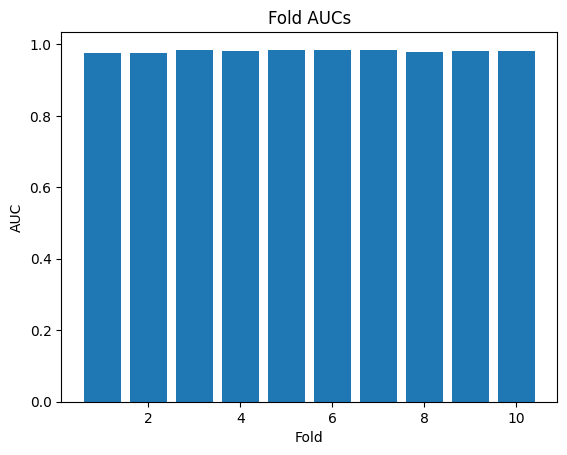

Best fold: 6 AUC: 0.9850739581027086
Classification report (best fold):
              precision    recall  f1-score      support
0              0.944676  0.931070  0.937824   972.000000
1              0.943460  0.954740  0.949066  1171.000000
accuracy       0.944004  0.944004  0.944004     0.944004
macro avg      0.944068  0.942905  0.943445  2143.000000
weighted avg   0.944012  0.944004  0.943967  2143.000000


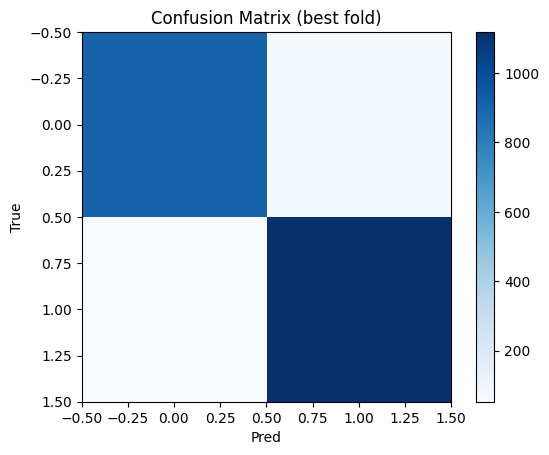

In [24]:
# Cell 13: simple plotting of fold metrics
import matplotlib.pyplot as plt
with open(save_dir/"cv_results.pkl","rb") as f:
    res = pickle.load(f)

# aggregate AUCs
aucs = [r['auc'] for r in res]
plt.figure()
plt.bar(range(1,len(aucs)+1), aucs)
plt.xlabel("Fold"); plt.ylabel("AUC"); plt.title("Fold AUCs")
plt.savefig(save_dir/"fold_aucs.png", dpi=150)
plt.show()

# show confusion matrix of best fold
best = max(res, key=lambda x: x['auc'])
print("Best fold:", best['fold'], "AUC:", best['auc'])
print("Classification report (best fold):")
print(pd.DataFrame(best['report']).T)
cm = best['cm']
plt.figure()
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.colorbar()
plt.xlabel("Pred"); plt.ylabel("True"); plt.title("Confusion Matrix (best fold)")
plt.savefig(save_dir/"best_confusion.png", dpi=150)
plt.show()


In [25]:
# Cell 14: final save and example report
print("Best model saved at:", best_overall["model_path"])
# load and show sample predictions with that model (if desired)
final_model = BiLSTMClassifier(INPUT_DIM).to(device)
final_model.load_state_dict(torch.load(best_overall["model_path"]))
final_model.eval()
# Optionally export to ONNX if requested (skipped per choice)


Best model saved at: results_bilstm\best_fold6.pt


BiLSTMClassifier(
  (lstm): LSTM(28, 256, num_layers=2, batch_first=True, dropout=0.4, bidirectional=True)
  (fc): Sequential(
    (0): Linear(in_features=512, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)

Best fold: 6 | AUC: 0.985


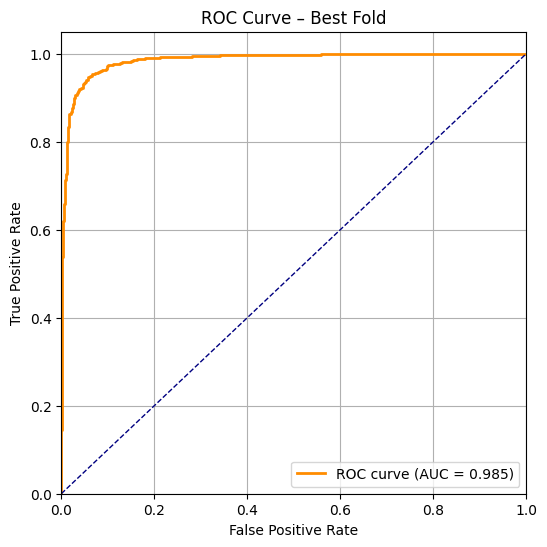

In [26]:
# Cell A: Plot ROC curve for best fold
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Load results
with open(save_dir / "cv_results.pkl", "rb") as f:
    res = pickle.load(f)

best = max(res, key=lambda x: x['auc'])
y_true = []
y_score = []

# Reload test predictions for best fold
best_fold = best['fold']
print(f"Best fold: {best_fold} | AUC: {best['auc']:.3f}")

# Extract test data from saved fold (re-run same split for ROC)
from sklearn.model_selection import StratifiedKFold
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
fold = 0
for train_idx, test_idx in skf.split(X_scaled, y):
    fold += 1
    if fold == best_fold:
        X_test = X_scaled[test_idx]
        y_test = y[test_idx]
        break

# Reload best model
best_model_path = best['model_path']
model = BiLSTMClassifier(X_scaled.shape[1]).to(device)
model.load_state_dict(torch.load(best_model_path))
model.eval()

with torch.no_grad():
    xb = torch.from_numpy(X_test).to(device).float()
    preds = torch.sigmoid(model(xb)).cpu().numpy().flatten()

fpr, tpr, thresholds = roc_curve(y_test, preds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0,1], [0,1], color='navy', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Best Fold')
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig(save_dir / "roc_curve_best_fold.png", dpi=150)
plt.show()
